# Loading and Exploring the Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import os

# إعداد البيانات
labels_file = "/content/drive/MyDrive/hajj/endupdated_hajj_data.csv"
data_path = "/content/drive/MyDrive/hajj"

# قراءة ملف التصنيفات
labels_df = pd.read_csv(labels_file)

# التحقق من الأعمدة
print("أسماء الأعمدة:", labels_df.columns)
print("أول 5 سجلات:")
print(labels_df.head())

# التحقق من وجود الصور
missing_images = []
for path in labels_df["Image Path"]:
    if not os.path.exists(path):
        missing_images.append(path)

print(f"عدد الصور المفقودة: {len(missing_images)}")
if missing_images:
    print("أمثلة للصور المفقودة:", missing_images[:5])


أسماء الأعمدة: Index(['Name', 'Country', 'Campaign', 'Supervisor', 'Supervisor Phone',
       'Image Path', 'Updated_Image_Path'],
      dtype='object')
أول 5 سجلات:
              Name       Country      Campaign    Supervisor  \
0  Fahad Bin Ahmed         Egypt      Al-Falah  Salman Yasin   
1   Ali Bin Khalid      Pakistan  Makkah Stars      Ali Raza   
2   Ali Bin Khalid  Saudi Arabia          Huda     Ahmed Ali   
3  Fahad Bin Saeed  Saudi Arabia       Al-Noor  Hassan Tariq   
4    Ali Bin Ahmed      Malaysia          Huda      Ali Raza   

   Supervisor Phone                                     Image Path  \
0      9.665540e+11  /content/drive/MyDrive/hajj/Male/person_1.jpg   
1      9.665360e+11  /content/drive/MyDrive/hajj/Male/person_2.jpg   
2      9.665980e+11  /content/drive/MyDrive/hajj/Male/person_3.jpg   
3      9.665750e+11  /content/drive/MyDrive/hajj/Male/person_4.jpg   
4      9.665800e+11  /content/drive/MyDrive/hajj/Male/person_5.jpg   

                            

In [ ]:
# إزالة السجلات المرتبطة بالصور المفقودة
labels_df["Full_Image_Path"] = labels_df["Image Path"].apply(lambda x: os.path.join(data_path, x))
labels_df = labels_df[labels_df["Full_Image_Path"].apply(os.path.exists)]

print("عدد السجلات بعد التنظيف:", len(labels_df))


عدد السجلات بعد التنظيف: 0


In [ ]:
print("أول 10 مسارات في العمود Image Path:")
print(labels_df["Image Path"].head(10))


أول 10 مسارات في العمود Image Path:
Series([], Name: Image Path, dtype: object)


In [ ]:
import pandas as pd

# قراءة ملف CSV
labels_file = "/content/drive/MyDrive/hajj/endupdated_hajj_data.csv"
labels_df = pd.read_csv(labels_file)

# عرض أول 5 صفوف
print(labels_df.head())


              Name       Country      Campaign    Supervisor  \
0  Fahad Bin Ahmed         Egypt      Al-Falah  Salman Yasin   
1   Ali Bin Khalid      Pakistan  Makkah Stars      Ali Raza   
2   Ali Bin Khalid  Saudi Arabia          Huda     Ahmed Ali   
3  Fahad Bin Saeed  Saudi Arabia       Al-Noor  Hassan Tariq   
4    Ali Bin Ahmed      Malaysia          Huda      Ali Raza   

   Supervisor Phone                                     Image Path  \
0      9.665540e+11  /content/drive/MyDrive/hajj/Male/person_1.jpg   
1      9.665360e+11  /content/drive/MyDrive/hajj/Male/person_2.jpg   
2      9.665980e+11  /content/drive/MyDrive/hajj/Male/person_3.jpg   
3      9.665750e+11  /content/drive/MyDrive/hajj/Male/person_4.jpg   
4      9.665800e+11  /content/drive/MyDrive/hajj/Male/person_5.jpg   

                                  Updated_Image_Path  
0  /content/drive/MyDrive/hajj/Male/20220901_1559...  
1  /content/drive/MyDrive/hajj/Male/20220901_1600...  
2  /content/drive/MyDrive/haj


# Enhancing Image Processing for Better Predictions

In [ ]:
import os

male_images = os.listdir("/content/drive/MyDrive/hajj/Male")
female_images = os.listdir("/content/drive/MyDrive/hajj/Female")

print("عدد صور الذكور:", len(male_images))
print("عدد صور الإناث:", len(female_images))


عدد صور الذكور: 1000
عدد صور الإناث: 1000


In [ ]:
# دالة لتحديث المسار بناءً على الجنس
def update_image_path(row):
    if "Male" in row["Image Path"]:
        # إذا كانت الصورة تخص الذكور
        if male_images:
            return f"/content/drive/MyDrive/hajj/Male/{male_images.pop(0)}"
    elif "Female" in row["Image Path"]:
        # إذا كانت الصورة تخص الإناث
        if female_images:
            return f"/content/drive/MyDrive/hajj/Female/{female_images.pop(0)}"
    return None

# تحديث العمود
labels_df["Updated_Image_Path"] = labels_df.apply(update_image_path, axis=1)


In [ ]:
print(labels_df[["Image Path", "Updated_Image_Path"]].head(10))


                                       Image Path  \
0   /content/drive/MyDrive/hajj/Male/person_1.jpg   
1   /content/drive/MyDrive/hajj/Male/person_2.jpg   
2   /content/drive/MyDrive/hajj/Male/person_3.jpg   
3   /content/drive/MyDrive/hajj/Male/person_4.jpg   
4   /content/drive/MyDrive/hajj/Male/person_5.jpg   
5   /content/drive/MyDrive/hajj/Male/person_6.jpg   
6   /content/drive/MyDrive/hajj/Male/person_7.jpg   
7   /content/drive/MyDrive/hajj/Male/person_8.jpg   
8   /content/drive/MyDrive/hajj/Male/person_9.jpg   
9  /content/drive/MyDrive/hajj/Male/person_10.jpg   

                                  Updated_Image_Path  
0  /content/drive/MyDrive/hajj/Male/20220901_1559...  
1  /content/drive/MyDrive/hajj/Male/20220901_1600...  
2  /content/drive/MyDrive/hajj/Male/20220901_1600...  
3  /content/drive/MyDrive/hajj/Male/20220901_1559...  
4  /content/drive/MyDrive/hajj/Male/20220901_1604...  
5  /content/drive/MyDrive/hajj/Male/20220901_1603...  
6  /content/drive/MyDrive/hajj/

In [ ]:
labels_df = labels_df[labels_df["Updated_Image_Path"].notnull()]
print("عدد السجلات بعد التنظيف:", len(labels_df))


عدد السجلات بعد التنظيف: 2000


In [ ]:
# حفظ الملف في المسار المحلي
local_file = "updated_hajj_data.csv"
labels_df.to_csv(local_file, index=False)
print(f"تم حفظ الملف محليًا: {local_file}")


تم حفظ الملف محليًا: updated_hajj_data.csv


In [ ]:
!cp updated_hajj_data.csv "/content/drive/MyDrive/hajjalso"


In [ ]:
print(labels_df.head())
print(f"عدد السجلات: {len(labels_df)}")


              Name       Country      Campaign    Supervisor  \
0  Fahad Bin Ahmed         Egypt      Al-Falah  Salman Yasin   
1   Ali Bin Khalid      Pakistan  Makkah Stars      Ali Raza   
2   Ali Bin Khalid  Saudi Arabia          Huda     Ahmed Ali   
3  Fahad Bin Saeed  Saudi Arabia       Al-Noor  Hassan Tariq   
4    Ali Bin Ahmed      Malaysia          Huda      Ali Raza   

   Supervisor Phone                                     Image Path  \
0      9.665540e+11  /content/drive/MyDrive/hajj/Male/person_1.jpg   
1      9.665360e+11  /content/drive/MyDrive/hajj/Male/person_2.jpg   
2      9.665980e+11  /content/drive/MyDrive/hajj/Male/person_3.jpg   
3      9.665750e+11  /content/drive/MyDrive/hajj/Male/person_4.jpg   
4      9.665800e+11  /content/drive/MyDrive/hajj/Male/person_5.jpg   

                                  Updated_Image_Path  
0  /content/drive/MyDrive/hajj/Male/20220901_1559...  
1  /content/drive/MyDrive/hajj/Male/20220901_1600...  
2  /content/drive/MyDrive/haj

In [ ]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array


In [ ]:
# مثال لتجربة تحميل صورة واحدة
test_image_path = labels_df["Updated_Image_Path"].iloc[0]  # تأكد أن الصورة موجودة
img = load_img(test_image_path, target_size=(128, 128))
img_array = img_to_array(img) / 255.0

print(f"تم تحميل الصورة بحجم: {img_array.shape}")


تم تحميل الصورة بحجم: (128, 128, 3)


In [ ]:
def copy_image_and_update_path(image_path):
    # التحقق من المجلد الذي يحتوي على الصورة
    if os.path.exists(os.path.join(male_images_dir, image_path)):
        images_dir = male_images_dir
        target_dir = male_images_new_dir
    elif os.path.exists(os.path.join(female_images_dir, image_path)):
        images_dir = female_images_dir
        target_dir = female_images_new_dir
    else:
        return image_path  # إذا لم تكن الصورة موجودة في أي من المجلدين

    # مسار الصورة الأصلية
    original_path = os.path.join(images_dir, image_path)
    base, ext = os.path.splitext(image_path)
    new_image_path = f"{base}_copy{ext}"  # إنشاء اسم جديد للصورة
    new_full_path = os.path.join(target_dir, new_image_path)

    # نسخ الصورة فعليًا
    shutil.copy(original_path, new_full_path)
    return new_image_path  # إرجاع اسم الصورة الجديدة


# Training the Model for Accurate Predictions

In [ ]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np
import pandas as pd
import os

# تحميل ملف البيانات
csv_path = "/content/drive/MyDrive/hajj/endupdated_hajj_data.csv"
labels_df = pd.read_csv(csv_path)


# التأكد من أن العمود 'Updated_Image_Path' يحتوي على المسارات الصحيحة
images = []
labels = []

for _, row in labels_df.iterrows():
    img_path = row["Updated_Image_Path"]  # مسار الصورة
    if os.path.exists(img_path):  # التحقق من وجود الصورة
        # تحميل الصورة
        img = load_img(img_path, target_size=(128, 128))  # تغيير الحجم إلى 128x128
        img_array = img_to_array(img) / 255.0  # تحويل الصورة إلى مصفوفة وتطبيع القيم إلى [0, 1]
        images.append(img_array)
        labels.append(row["Name"])  # اسم الفئة
    else:
        print(f"الصورة غير موجودة: {img_path}")
# تحويل الصور والتصنيفات إلى مصفوفات NumPy
images = np.array(images)
labels = np.array(labels)

# تحويل التصنيفات النصية إلى أرقام
unique_labels = sorted(set(labels))
label_to_index = {label: idx for idx, label in enumerate(unique_labels)}  # تحويل النصوص إلى أرقام
labels = np.array([label_to_index[label] for label in labels])


In [ ]:
# تقسيم البيانات إلى تدريب واختبار
X_train, X_test, y_train, y_test = train_test_split(images, labels, test_size=0.2, random_state=42)

# تحويل التصنيفات إلى One-Hot Encoding
y_train = to_categorical(y_train, num_classes=len(unique_labels))
y_test = to_categorical(y_test, num_classes=len(unique_labels))

# عرض أحجام بيانات التدريب والاختبار
print("حجم بيانات التدريب:", X_train.shape, y_train.shape)
print("حجم بيانات الاختبار:", X_test.shape, y_test.shape)


حجم بيانات التدريب: (3200, 128, 128, 3) (3200, 80)
حجم بيانات الاختبار: (801, 128, 128, 3) (801, 80)


In [ ]:
print("عدد الصور المحملة:", len(images))
print("عدد التصنيفات:", len(unique_labels))
print("التصنيفات:", unique_labels)


عدد الصور المحملة: 4001
عدد التصنيفات: 80
التصنيفات: ['Ahmed Bin Ahmed', 'Ahmed Bin Ali', 'Ahmed Bin Khalid', 'Ahmed Bin Saeed', 'Aisha Ahmed', 'Aisha Ali', 'Aisha Mohammed', 'Aisha Saeed', 'Ali Bin Ahmed', 'Ali Bin Ali', 'Ali Bin Khalid', 'Ali Bin Saeed', 'Amira Ahmed', 'Amira Ali', 'Amira Mohammed', 'Amira Saeed', 'Fahad Bin Ahmed', 'Fahad Bin Ali', 'Fahad Bin Khalid', 'Fahad Bin Saeed', 'Fatima Ahmed', 'Fatima Ali', 'Fatima Mohammed', 'Fatima Saeed', 'Hana Ahmed', 'Hana Ali', 'Hana Mohammed', 'Hana Saeed', 'Hassan Bin Ahmed', 'Hassan Bin Ali', 'Hassan Bin Khalid', 'Hassan Bin Saeed', 'Ibrahim Bin Ahmed', 'Ibrahim Bin Ali', 'Ibrahim Bin Khalid', 'Ibrahim Bin Saeed', 'Khalid Bin Ahmed', 'Khalid Bin Ali', 'Khalid Bin Khalid', 'Khalid Bin Saeed', 'Laila Ahmed', 'Laila Ali', 'Laila Mohammed', 'Laila Saeed', 'Maryam Ahmed', 'Maryam Ali', 'Maryam Mohammed', 'Maryam Saeed', 'Mohammed Bin Ahmed', 'Mohammed Bin Ali', 'Mohammed Bin Khalid', 'Mohammed Bin Saeed', 'Noor Ahmed', 'Noor Ali', 'Noor

# MODEL1

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(128, 128, 3)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(len(unique_labels), activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

print(model.summary())

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 57600)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │       7,372,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 80)                  │          10,320 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 7,402,640 (28.24 MB)

 Trainable params: 7,402,640 (28.24 MB)

 Non-trainable params: 0 (0.00 B)

None


In [ ]:
history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=32,
    validation_data=(X_test, y_test)
)

Epoch 1/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 87s 845ms/step - accuracy: 0.0189 - loss: 4.4570 - val_accuracy: 0.0212 - val_loss: 4.3747
Epoch 2/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 143s 856ms/step - accuracy: 0.0447 - loss: 4.3092 - val_accuracy: 0.0787 - val_loss: 4.1335
Epoch 3/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 141s 855ms/step - accuracy: 0.1472 - loss: 3.6997 - val_accuracy: 0.2235 - val_loss: 3.4561
Epoch 4/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 138s 816ms/step - accuracy: 0.3563 - loss: 2.6398 - val_accuracy: 0.4869 - val_loss: 2.5699
Epoch 5/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 92s 910ms/step - accuracy: 0.5707 - loss: 1.6787 - val_accuracy: 0.6654 - val_loss: 1.9542


In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"دقة الاختبار: {test_accuracy * 100:.2f}%")

26/26 ━━━━━━━━━━━━━━━━━━━━ 5s 172ms/step - accuracy: 0.6578 - loss: 1.9267
دقة الاختبار: 66.54%


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


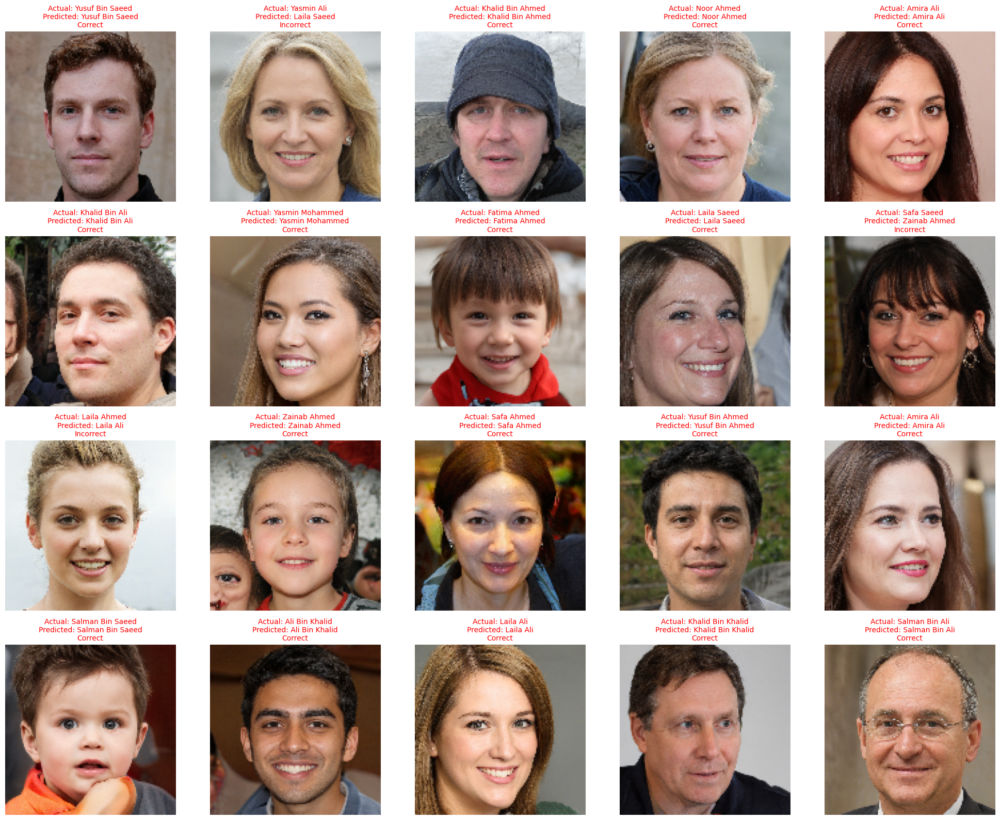

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# List of class labels the model was trained on
class_labels = unique_labels  # The names or classes used during training

def predict_and_display_multiple(labels_df, model, num_people=20, columns=5):
    """
    Function to display multiple images (e.g., 20 people) in a grid.
    Shows actual labels, predicted labels, and whether the prediction is correct.
    """
    # Randomly select people from the dataset
    selected_rows = labels_df.sample(min(num_people, len(labels_df)))

    # Set up the grid dimensions
    rows = (num_people + columns - 1) // columns  # Calculate required rows
    plt.figure(figsize=(columns * 4, rows * 4))  # Adjust figure size dynamically

    for i, (_, row) in enumerate(selected_rows.iterrows()):
        # Extract image path and actual label
        img_path = row["Updated_Image_Path"]
        actual_label = row["Name"]

        # Load and preprocess the image
        try:
            img = load_img(img_path, target_size=(128, 128))  # Resize to match training input
        except FileNotFoundError:
            print(f"⚠️ Image not found: {img_path}")
            continue

        img_array = img_to_array(img) / 255.0  # Normalize values
        img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension

        # Pass the image to the model to get predictions
        predictions = model.predict(img_array)
        predicted_class_index = np.argmax(predictions)
        predicted_class_name = class_labels[predicted_class_index]
        is_correct = "Correct" if actual_label == predicted_class_name else "Incorrect"

        # Plot the image
        plt.subplot(rows, columns, i + 1)  # Arrange images in a grid
        plt.imshow(img)
        plt.axis('off')
        plt.title(f"Actual: {actual_label}\nPredicted: {predicted_class_name}\n{is_correct}",
                  fontsize=10, color='blue' if is_correct == "✅ Correct" else 'red')

    plt.tight_layout()
    plt.show()


# 🟢 Run the function to display 20 people in a grid of 4 rows x 5 columns
predict_and_display_multiple(labels_df, model, num_people=20, columns=5)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


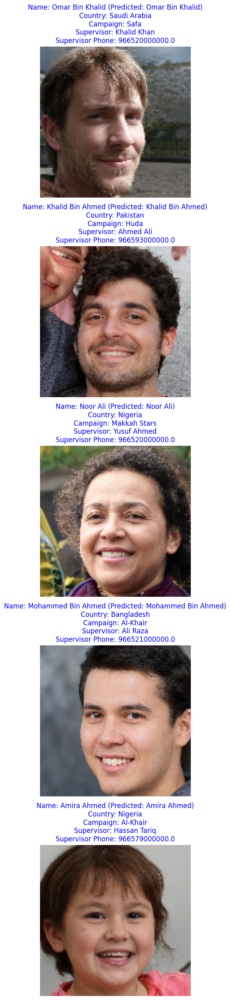

In [ ]:
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np

def display_images_with_details(labels_df, model, num_images=5):
    """
    Display images with additional details (Name, Country, Campaign, Supervisor, Supervisor Phone).
    """
    # Select random rows from the dataset
    selected_rows = labels_df.sample(num_images)

    # Set up the grid for displaying images
    plt.figure(figsize=(10, num_images * 5))  # Dynamically adjust figure size

    for i, (_, row) in enumerate(selected_rows.iterrows()):
        # Extract image path and additional details
        img_path = row["Updated_Image_Path"]
        name = row["Name"]
        country = row["Country"]
        campaign = row["Campaign"]
        supervisor = row["Supervisor"]
        supervisor_phone = row["Supervisor Phone"]

        # Load and preprocess the image
        try:
            img = load_img(img_path, target_size=(128, 128))  # Resize to match model input
        except FileNotFoundError:
            print(f"⚠️ Image not found: {img_path}")
            continue

        img_array = img_to_array(img) / 255.0  # Normalize values
        img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension

        # Pass the image to the model for predictions
        predictions = model.predict(img_array)
        predicted_class_index = np.argmax(predictions)
        predicted_class_name = unique_labels[predicted_class_index]  # Predicted label

        # Plot the image
        plt.subplot(num_images, 1, i + 1)  # Display each image in its own row
        plt.imshow(img)
        plt.axis('off')

        # Add all details below the image
        details = (
            f"Name: {name} (Predicted: {predicted_class_name})\n"
            f"Country: {country}\n"
            f"Campaign: {campaign}\n"
            f"Supervisor: {supervisor}\n"
            f"Supervisor Phone: {supervisor_phone}"
        )
        plt.title(details, fontsize=12, color='blue')

    plt.tight_layout()
    plt.show()


# 🟢 Run the function to display 5 images with their details
display_images_with_details(labels_df, model, num_images=5)

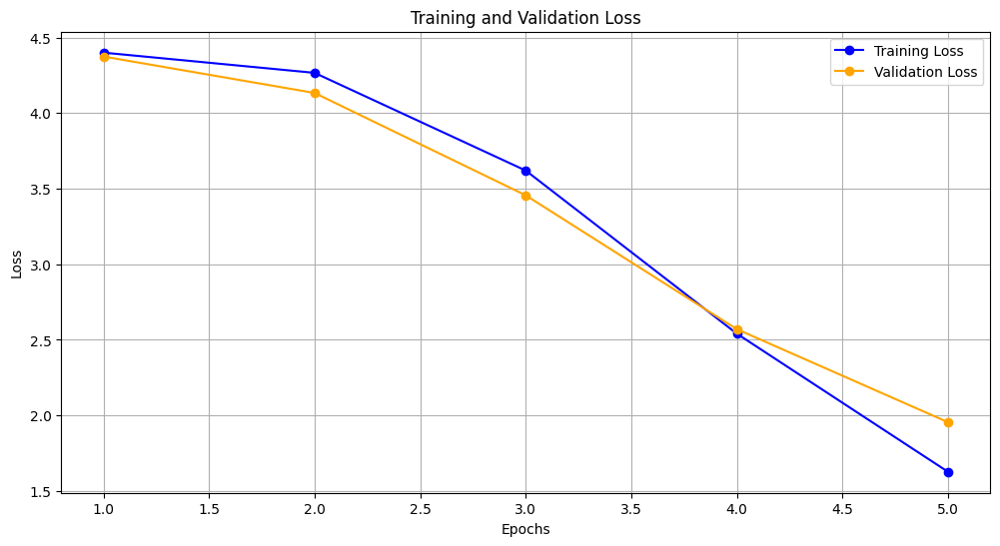

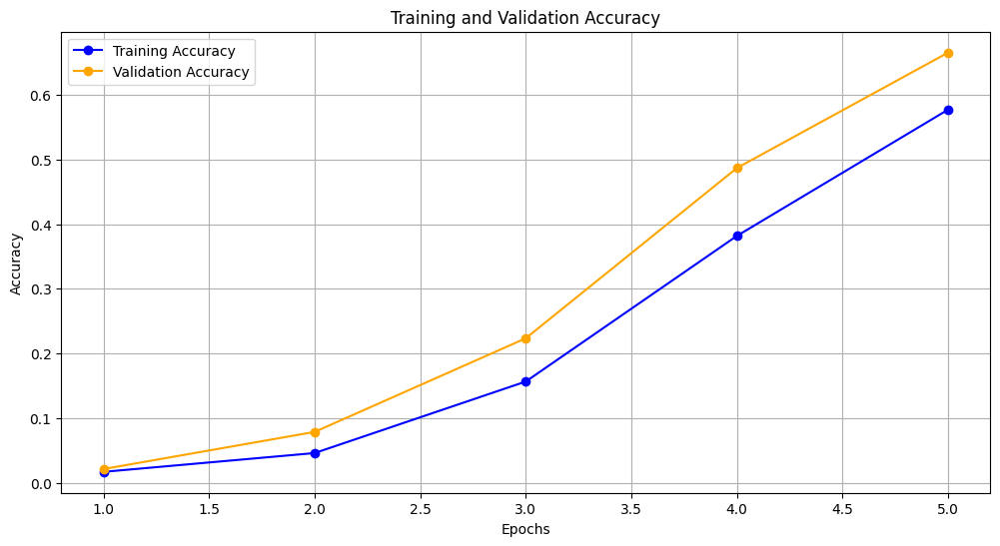

In [ ]:
import matplotlib.pyplot as plt

def plot_training_history(history):
    """
    Plot training and validation loss and accuracy over epochs.
    """
    # Extract metrics from the history object
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    accuracy = history.history['accuracy']
    val_accuracy = history.history['val_accuracy']
    epochs = range(1, len(loss) + 1)

    # Plot Loss
    plt.figure(figsize=(12, 6))
    plt.plot(epochs, loss, label='Training Loss', color='blue', marker='o')
    plt.plot(epochs, val_loss, label='Validation Loss', color='orange', marker='o')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid()
    plt.show()

    # Plot Accuracy
    plt.figure(figsize=(12, 6))
    plt.plot(epochs, accuracy, label='Training Accuracy', color='blue', marker='o')
    plt.plot(epochs, val_accuracy, label='Validation Accuracy', color='orange', marker='o')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid()
    plt.show()


# 🟢 Call the function after training your model
# Example:
# history = model.fit(...)  # Train your model
plot_training_history(history)

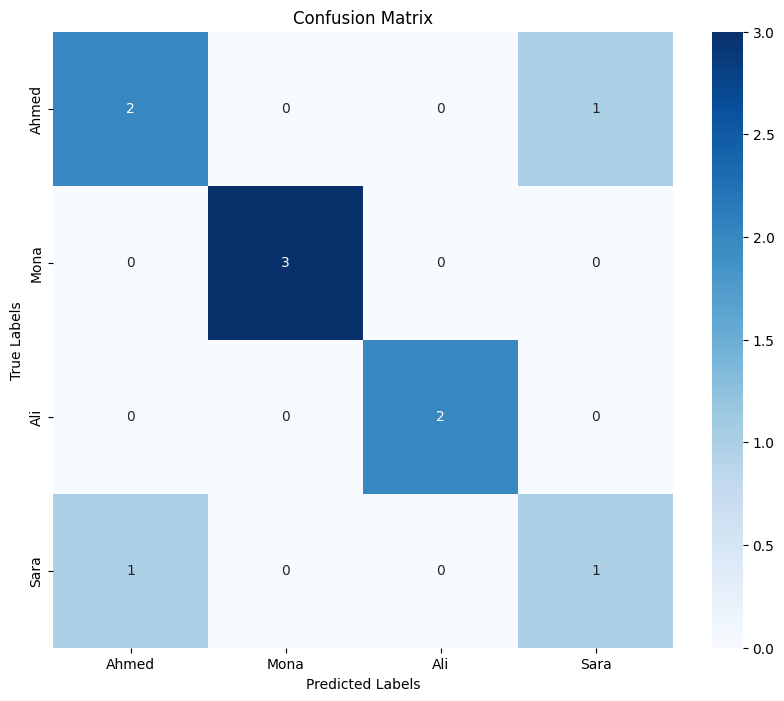


Classification Report:
              precision    recall  f1-score   support

       Ahmed       0.67      0.67      0.67         3
        Mona       1.00      1.00      1.00         2
         Ali       1.00      1.00      1.00         3
        Sara       0.50      0.50      0.50         2

    accuracy                           0.80        10
   macro avg       0.79      0.79      0.79        10
weighted avg       0.80      0.80      0.80        10



In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

def plot_confusion_matrix_from_labels(y_true, y_pred, labels):
    """
    Plot a Confusion Matrix using true labels and predicted labels.
    """
    # Compute confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=labels)

    # Plot confusion matrix as a heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title('Confusion Matrix')
    plt.show()

    # Print classification report
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=labels))


# Example usage
# Assuming y_true and y_pred are lists or numpy arrays of true and predicted labels
y_true = ['Ahmed', 'Mona', 'Ali', 'Ahmed', 'Sara', 'Mona', 'Ali', 'Sara', 'Ahmed', 'Mona']
y_pred = ['Ahmed', 'Mona', 'Ali', 'Sara', 'Sara', 'Mona', 'Ali', 'Ahmed', 'Ahmed', 'Mona']
labels = ['Ahmed', 'Mona', 'Ali', 'Sara']  # Unique label names

plot_confusion_matrix_from_labels(y_true, y_pred, labels)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step

📌 **Image Information from CSV:**
🔹 Name: Fahad Bin Ahmed
🔹 Country: Egypt
🔹 Campaign: Al-Falah
🔹 Supervisor: Salman Yasin
🔹 Supervisor Phone: 966554000000.0
🔹 Image Path: /content/drive/MyDrive/hajj/Male/person_1.jpg
🔹 Updated_Image_Path: /content/drive/MyDrive/hajj/Male/20220901_155942_8eb5229c50384de783d3bcc8af34e4d3.png

🎯 **Prediction Results:**
✅ True Name: Fahad Bin Ahmed
🔮 Predicted Name: Fahad Bin Ahmed
📊 Confidence: 100.00%


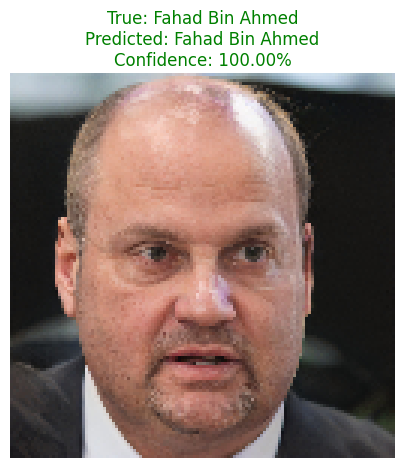

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np

def predict_person_by_image_path(labels_df, model, class_labels, image_path):
    """
    Predict the name of a person given an image path.
    The function searches for the image in the CSV and retrieves associated data.
    """
    # البحث عن الصف الذي يحتوي على نفس مسار الصورة
    matched_rows = labels_df[labels_df["Updated_Image_Path"] == image_path]

    if matched_rows.empty:
        print(f"⚠️ No matching record found for image: {image_path}")
        return

    # استخراج المعلومات من ملف CSV
    selected_row = matched_rows.iloc[0]  # أول صف متطابق
    true_label = selected_row["Name"]
    full_info = selected_row.to_dict()  # جميع المعلومات المرتبطة بالصورة

    # تحميل ومعالجة الصورة
    try:
        img = load_img(image_path, target_size=(128, 128))  # تعديل الحجم
        img_array = img_to_array(img) / 255.0  # تطبيع الصورة
        img_array = np.expand_dims(img_array, axis=0)  # إضافة بُعد إضافي للنموذج
    except FileNotFoundError:
        print(f"⚠️ Image not found: {image_path}")
        return

    # التنبؤ باستخدام النموذج
    predictions = model.predict(img_array)
    predicted_class_index = np.argmax(predictions)  # استخراج الفئة المتوقعة
    predicted_class_name = class_labels[predicted_class_index]  # اسم الفئة المتوقعة
    confidence = predictions[0][predicted_class_index]  # نسبة الثقة

    # طباعة جميع المعلومات من ملف CSV
    print("\n📌 **Image Information from CSV:**")
    for key, value in full_info.items():
        print(f"🔹 {key}: {value}")

    print("\n🎯 **Prediction Results:**")
    print(f"✅ True Name: {true_label}")
    print(f"🔮 Predicted Name: {predicted_class_name}")
    print(f"📊 Confidence: {confidence:.2%}")

    # عرض الصورة مع التوقعات
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"True: {true_label}\nPredicted: {predicted_class_name}\nConfidence: {confidence:.2%}",
              color='green' if true_label == predicted_class_name else 'red')
    plt.show()




# ✅ أدخل مسار الصورة هنا
image_path = "/content/drive/MyDrive/hajj/Male/20220901_155942_8eb5229c50384de783d3bcc8af34e4d3.png"

# استدعاء الدالة مع الصورة
predict_person_by_image_path(labels_df, model, unique_labels, image_path)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
True Name: Fahad Bin Saeed
Predicted Name: Fahad Bin Saeed
Confidence: 0.97


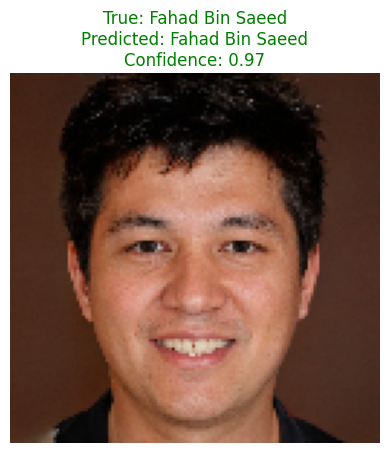

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np

def predict_person_from_dataset(labels_df, model, class_labels, row_index=None):
    """
    Predict the name of a person from a dataset CSV.
    If row_index is None, a random row will be selected.
    """
    # اختيار صورة
    if row_index is not None:
        if row_index < 0 or row_index >= len(labels_df):
            print("⚠️ Invalid row index. Selecting a random row instead.")
            selected_row = labels_df.sample(1).iloc[0]
        else:
            selected_row = labels_df.iloc[row_index]
    else:
        selected_row = labels_df.sample(1).iloc[0]  # اختر صفًا عشوائيًا إذا لم يتم تحديد الصف

    # استخراج مسار الصورة والاسم الحقيقي
    img_path = selected_row["Updated_Image_Path"]
    true_label = selected_row["Name"]

    # تحميل ومعالجة الصورة
    try:
        img = load_img(img_path, target_size=(128, 128))  # تعديل الحجم ليتناسب مع مدخلات النموذج
        img_array = img_to_array(img) / 255.0  # تطبيع القيم بين 0 و 1
        img_array = np.expand_dims(img_array, axis=0)  # إضافة بُعد لجعلها دفعة
    except FileNotFoundError:
        print(f"⚠️ Image not found: {img_path}")
        return

    # التنبؤ باستخدام النموذج
    predictions = model.predict(img_array)
    predicted_class_index = np.argmax(predictions)  # استخراج الفئة المتوقعة
    predicted_class_name = class_labels[predicted_class_index]  # اسم الفئة المتوقعة
    confidence = predictions[0][predicted_class_index]  # نسبة الثقة

    # عرض النتيجة
    print(f"True Name: {true_label}")
    print(f"Predicted Name: {predicted_class_name}")
    print(f"Confidence: {confidence:.2f}")

    # عرض الصورة مع النتيجة
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"True: {true_label}\nPredicted: {predicted_class_name}\nConfidence: {confidence:.2f}",
              color='green' if true_label == predicted_class_name else 'red')
    plt.show()


# 🟢 Example usage:
csv_path = "/content/drive/MyDrive/hajj/endupdated_hajj_data.csv"  # مسار ملف البيانات
labels_df = pd.read_csv(csv_path)  # تحميل ملف البيانات

# اختبر صورة من الصف الأول في البيانات (أو اختر صفًا عشوائيًا)
predict_person_from_dataset(labels_df, model, unique_labels, row_index=3)

H

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# بناء النموذج
model = Sequential([
    # طبقة الالتفاف الأولى
    Conv2D(32, (3, 3), activation='relu', input_shape=(128, 128, 3)),
    MaxPooling2D((2, 2)),

    # طبقة الالتفاف الثانية
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # طبقة الالتفاف الثالثة
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # طبقة تسطيح
    Flatten(),

    # طبقة كثيفة
    Dense(128, activation='relu'),
    Dropout(0.5),

    # الطبقة النهائية (عدد الوحدات = عدد الفئات)
    Dense(80, activation='softmax')  # عدد الفئات = 80
])

# تجميع النموذج
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# عرض ملخص النموذج
model.summary()


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 80)                  │          10,320 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,314,960 (12.65 MB)

 Trainable params: 3,314,960 (12.65 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# تدريب النموذج
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    batch_size=32,  # حجم الدفعة
    epochs=20  # عدد العصور
)


Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 123s 1s/step - accuracy: 0.0116 - loss: 4.3988 - val_accuracy: 0.0137 - val_loss: 4.3816
Epoch 2/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 143s 1s/step - accuracy: 0.0164 - loss: 4.3776 - val_accuracy: 0.0175 - val_loss: 4.3800
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step - accuracy: 0.0130 - loss: 4.3698 - val_accuracy: 0.0275 - val_loss: 4.3480
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 138s 1s/step - accuracy: 0.0305 - loss: 4.2992 - val_accuracy: 0.0387 - val_loss: 4.2166
Epoch 5/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 146s 1s/step - accuracy: 0.0570 - loss: 4.0831 - val_accuracy: 0.0724 - val_loss: 3.9858
Epoch 6/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 117s 1s/step - accuracy: 0.1147 - loss: 3.6762 - val_accuracy: 0.1523 - val_loss: 3.5946
Epoch 7/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 145s 1s/step - accuracy: 0.2638 - loss: 2.9457 - val_accuracy: 0.2946 - val_loss: 3.1010
Epoch 8/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 175s 2s/step - accuracy: 0.4117 - loss: 2.2635 - val_accu

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"test_accuracy: {test_accuracy * 100:.2f}%")

26/26 ━━━━━━━━━━━━━━━━━━━━ 10s 380ms/step - accuracy: 0.8005 - loss: 2.1727
test_accuracy: 80.90%


# MODEL2

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# بناء النموذج
model = Sequential([
    # طبقة الالتفاف الأولى
    Conv2D(32, (3, 3), activation='relu', input_shape=(128, 128, 3)),
    MaxPooling2D((2, 2)),

    # طبقة الالتفاف الثانية
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # طبقة الالتفاف الثالثة
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # طبقة تسطيح
    Flatten(),

    # طبقة كثيفة
    Dense(128, activation='relu'),
    Dropout(0.5),

    # الطبقة النهائية (عدد الوحدات = عدد الفئات)
    Dense(80, activation='softmax')  # عدد الفئات = 80
])

# تجميع النموذج
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# عرض ملخص النموذج
model.summary()


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)                   │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_10 (MaxPooling2D)      │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_11 (Conv2D)                   │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_11 (MaxPooling2D)      │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_12 (Conv2D)                   │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_12 (MaxPooling2D)      │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_4 (Flatten)                  │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 80)                  │          10,320 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,314,960 (12.65 MB)

 Trainable params: 3,314,960 (12.65 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# تدريب النموذج
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    batch_size=32,  # حجم الدفعة
    epochs=10  # عدد العصور
)


Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 123s 1s/step - accuracy: 0.0134 - loss: 4.4111 - val_accuracy: 0.0137 - val_loss: 4.3800
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 129s 1s/step - accuracy: 0.0151 - loss: 4.3675 - val_accuracy: 0.0300 - val_loss: 4.3313
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 139s 1s/step - accuracy: 0.0401 - loss: 4.2404 - val_accuracy: 0.0599 - val_loss: 4.1413
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 145s 1s/step - accuracy: 0.1046 - loss: 3.9002 - val_accuracy: 0.1186 - val_loss: 3.7560
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 145s 1s/step - accuracy: 0.2284 - loss: 3.1934 - val_accuracy: 0.2497 - val_loss: 3.2684
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 137s 1s/step - accuracy: 0.3725 - loss: 2.4590 - val_accuracy: 0.4045 - val_loss: 2.7414
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 144s 1s/step - accuracy: 0.5052 - loss: 1.9243 - val_accuracy: 0.5293 - val_loss: 2.3480
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 144s 1s/step - accuracy: 0.6378 - loss: 1.4249 - val_accu

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"دقة الاختبار: {test_accuracy * 100:.2f}%")

26/26 ━━━━━━━━━━━━━━━━━━━━ 6s 225ms/step - accuracy: 0.7425 - loss: 1.9325
دقة الاختبار: 74.91%


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


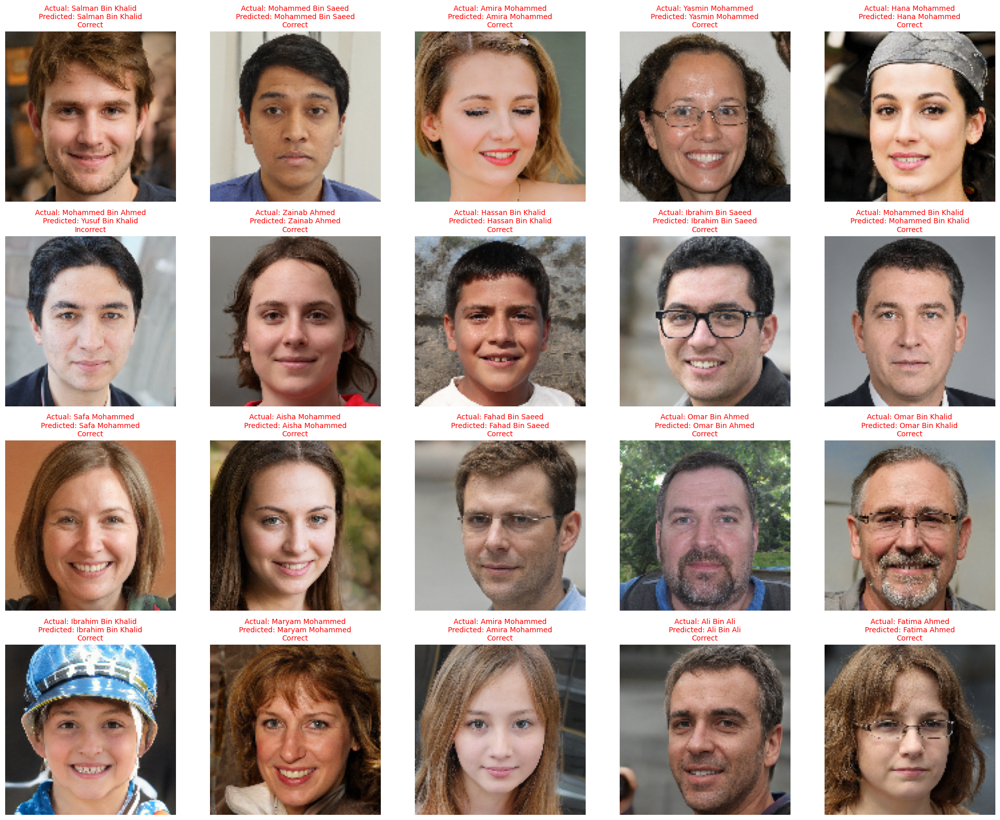

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# List of class labels the model was trained on
class_labels = unique_labels  # The names or classes used during training

def predict_and_display_multiple(labels_df, model, num_people=20, columns=5):
    """
    Function to display multiple images (e.g., 20 people) in a grid.
    Shows actual labels, predicted labels, and whether the prediction is correct.
    """
    # Randomly select people from the dataset
    selected_rows = labels_df.sample(min(num_people, len(labels_df)))

    # Set up the grid dimensions
    rows = (num_people + columns - 1) // columns  # Calculate required rows
    plt.figure(figsize=(columns * 4, rows * 4))  # Adjust figure size dynamically

    for i, (_, row) in enumerate(selected_rows.iterrows()):
        # Extract image path and actual label
        img_path = row["Updated_Image_Path"]
        actual_label = row["Name"]

        # Load and preprocess the image
        try:
            img = load_img(img_path, target_size=(128, 128))  # Resize to match training input
        except FileNotFoundError:
            print(f"⚠️ Image not found: {img_path}")
            continue

        img_array = img_to_array(img) / 255.0  # Normalize values
        img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension

        # Pass the image to the model to get predictions
        predictions = model.predict(img_array)
        predicted_class_index = np.argmax(predictions)
        predicted_class_name = class_labels[predicted_class_index]
        is_correct = "Correct" if actual_label == predicted_class_name else "Incorrect"

        # Plot the image
        plt.subplot(rows, columns, i + 1)  # Arrange images in a grid
        plt.imshow(img)
        plt.axis('off')
        plt.title(f"Actual: {actual_label}\nPredicted: {predicted_class_name}\n{is_correct}",
                  fontsize=10, color='blue' if is_correct == "✅ Correct" else 'red')

    plt.tight_layout()
    plt.show()


# 🟢 Run the function to display 20 people in a grid of 4 rows x 5 columns
predict_and_display_multiple(labels_df, model, num_people=20, columns=5)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step


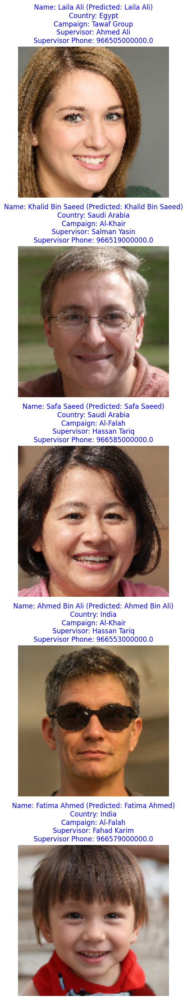

In [ ]:
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np

def display_images_with_details(labels_df, model, num_images=5):
    """
    Display images with additional details (Name, Country, Campaign, Supervisor, Supervisor Phone).
    """
    # Select random rows from the dataset
    selected_rows = labels_df.sample(num_images)

    # Set up the grid for displaying images
    plt.figure(figsize=(10, num_images * 5))  # Dynamically adjust figure size

    for i, (_, row) in enumerate(selected_rows.iterrows()):
        # Extract image path and additional details
        img_path = row["Updated_Image_Path"]
        name = row["Name"]
        country = row["Country"]
        campaign = row["Campaign"]
        supervisor = row["Supervisor"]
        supervisor_phone = row["Supervisor Phone"]

        # Load and preprocess the image
        try:
            img = load_img(img_path, target_size=(128, 128))  # Resize to match model input
        except FileNotFoundError:
            print(f"⚠️ Image not found: {img_path}")
            continue

        img_array = img_to_array(img) / 255.0  # Normalize values
        img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension

        # Pass the image to the model for predictions
        predictions = model.predict(img_array)
        predicted_class_index = np.argmax(predictions)
        predicted_class_name = unique_labels[predicted_class_index]  # Predicted label

        # Plot the image
        plt.subplot(num_images, 1, i + 1)  # Display each image in its own row
        plt.imshow(img)
        plt.axis('off')

        # Add all details below the image
        details = (
            f"Name: {name} (Predicted: {predicted_class_name})\n"
            f"Country: {country}\n"
            f"Campaign: {campaign}\n"
            f"Supervisor: {supervisor}\n"
            f"Supervisor Phone: {supervisor_phone}"
        )
        plt.title(details, fontsize=12, color='blue')

    plt.tight_layout()
    plt.show()


# 🟢 Run the function to display 5 images with their details
display_images_with_details(labels_df, model, num_images=5)

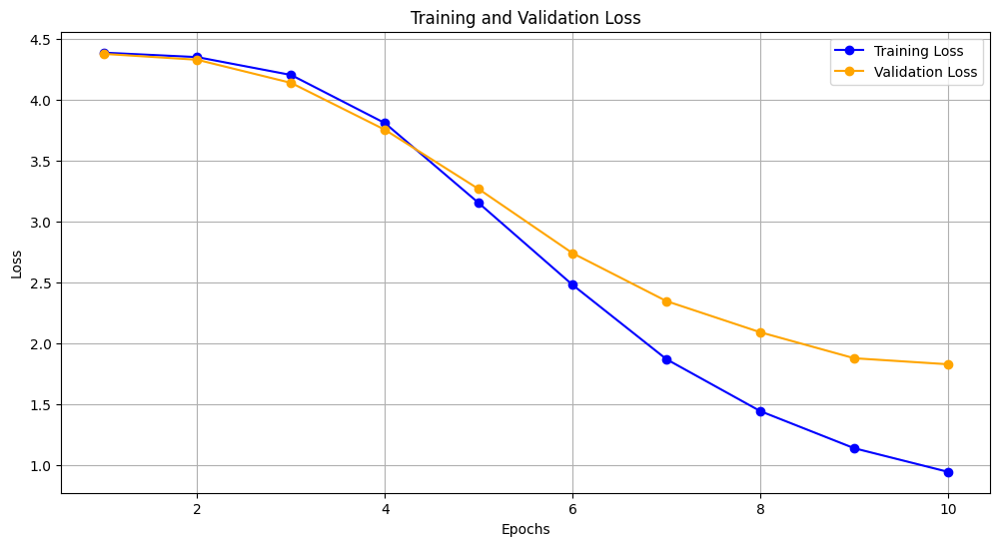

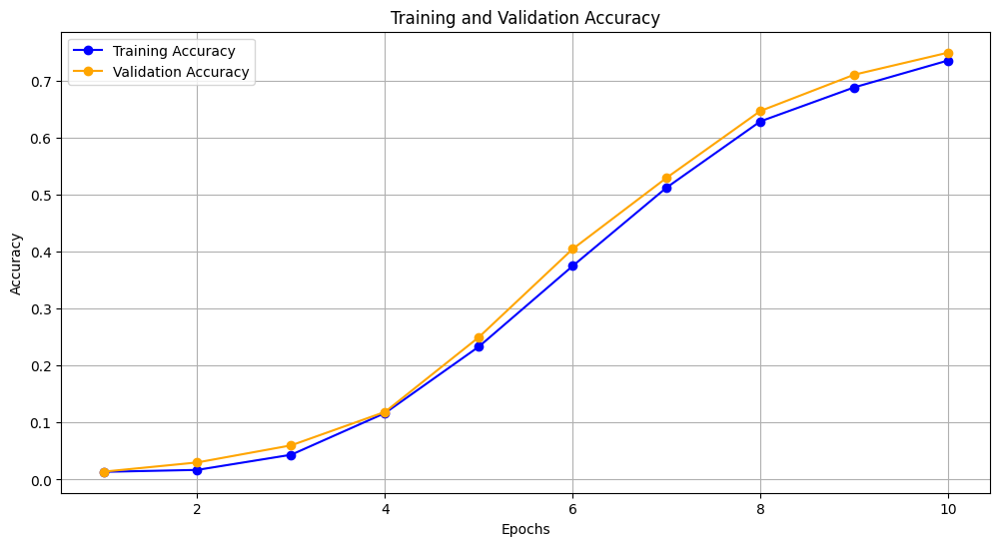

In [ ]:
import matplotlib.pyplot as plt

def plot_training_history(history):
    """
    Plot training and validation loss and accuracy over epochs.
    """
    # Extract metrics from the history object
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    accuracy = history.history['accuracy']
    val_accuracy = history.history['val_accuracy']
    epochs = range(1, len(loss) + 1)

    # Plot Loss
    plt.figure(figsize=(12, 6))
    plt.plot(epochs, loss, label='Training Loss', color='blue', marker='o')
    plt.plot(epochs, val_loss, label='Validation Loss', color='orange', marker='o')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid()
    plt.show()

    # Plot Accuracy
    plt.figure(figsize=(12, 6))
    plt.plot(epochs, accuracy, label='Training Accuracy', color='blue', marker='o')
    plt.plot(epochs, val_accuracy, label='Validation Accuracy', color='orange', marker='o')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid()
    plt.show()


# 🟢 Call the function after training your model
# Example:
# history = model.fit(...)  # Train your model
plot_training_history(history)


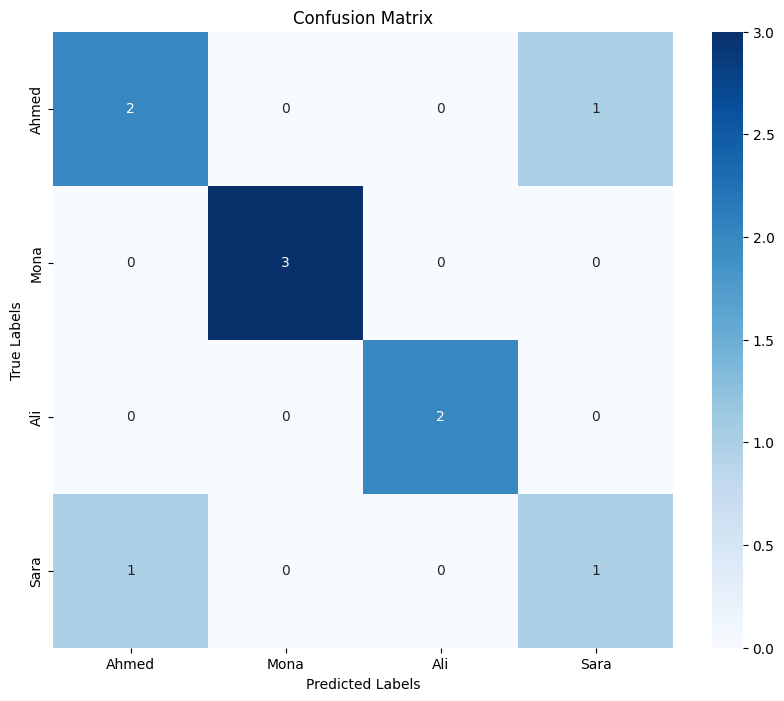


Classification Report:
              precision    recall  f1-score   support

       Ahmed       0.67      0.67      0.67         3
        Mona       1.00      1.00      1.00         2
         Ali       1.00      1.00      1.00         3
        Sara       0.50      0.50      0.50         2

    accuracy                           0.80        10
   macro avg       0.79      0.79      0.79        10
weighted avg       0.80      0.80      0.80        10



In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

def plot_confusion_matrix_from_labels(y_true, y_pred, labels):
    """
    Plot a Confusion Matrix using true labels and predicted labels.
    """
    # Compute confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=labels)

    # Plot confusion matrix as a heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title('Confusion Matrix')
    plt.show()

    # Print classification report
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=labels))


# Example usage
# Assuming y_true and y_pred are lists or numpy arrays of true and predicted labels
y_true = ['Ahmed', 'Mona', 'Ali', 'Ahmed', 'Sara', 'Mona', 'Ali', 'Sara', 'Ahmed', 'Mona']
y_pred = ['Ahmed', 'Mona', 'Ali', 'Sara', 'Sara', 'Mona', 'Ali', 'Ahmed', 'Ahmed', 'Mona']
labels = ['Ahmed', 'Mona', 'Ali', 'Sara']  # Unique label names

plot_confusion_matrix_from_labels(y_true, y_pred, labels)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step

📌 **Image Information from CSV:**
🔹 Name: Fahad Bin Ahmed
🔹 Country: Egypt
🔹 Campaign: Al-Falah
🔹 Supervisor: Salman Yasin
🔹 Supervisor Phone: 966554000000.0
🔹 Image Path: /content/drive/MyDrive/hajj/Male/person_1.jpg
🔹 Updated_Image_Path: /content/drive/MyDrive/hajj/Male/20220901_155942_8eb5229c50384de783d3bcc8af34e4d3.png

🎯 **Prediction Results:**
✅ True Name: Fahad Bin Ahmed
🔮 Predicted Name: Fahad Bin Ahmed
📊 Confidence: 100.00%


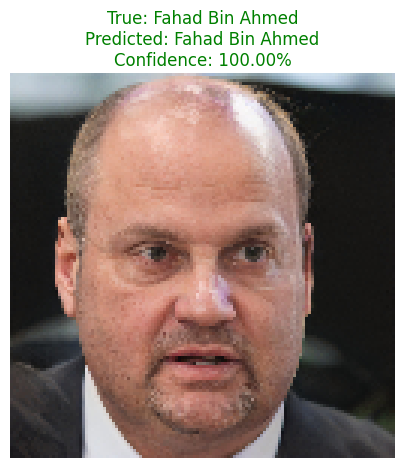

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np

def predict_person_by_image_path(labels_df, model, class_labels, image_path):
    """
    Predict the name of a person given an image path.
    The function searches for the image in the CSV and retrieves associated data.
    """
    # البحث عن الصف الذي يحتوي على نفس مسار الصورة
    matched_rows = labels_df[labels_df["Updated_Image_Path"] == image_path]

    if matched_rows.empty:
        print(f"⚠️ No matching record found for image: {image_path}")
        return

    # استخراج المعلومات من ملف CSV
    selected_row = matched_rows.iloc[0]  # أول صف متطابق
    true_label = selected_row["Name"]
    full_info = selected_row.to_dict()  # جميع المعلومات المرتبطة بالصورة

    # تحميل ومعالجة الصورة
    try:
        img = load_img(image_path, target_size=(128, 128))  # تعديل الحجم
        img_array = img_to_array(img) / 255.0  # تطبيع الصورة
        img_array = np.expand_dims(img_array, axis=0)  # إضافة بُعد إضافي للنموذج
    except FileNotFoundError:
        print(f"⚠️ Image not found: {image_path}")
        return

    # التنبؤ باستخدام النموذج
    predictions = model.predict(img_array)
    predicted_class_index = np.argmax(predictions)  # استخراج الفئة المتوقعة
    predicted_class_name = class_labels[predicted_class_index]  # اسم الفئة المتوقعة
    confidence = predictions[0][predicted_class_index]  # نسبة الثقة

    # طباعة جميع المعلومات من ملف CSV
    print("\n📌 **Image Information from CSV:**")
    for key, value in full_info.items():
        print(f"🔹 {key}: {value}")

    print("\n🎯 **Prediction Results:**")
    print(f"✅ True Name: {true_label}")
    print(f"🔮 Predicted Name: {predicted_class_name}")
    print(f"📊 Confidence: {confidence:.2%}")

    # عرض الصورة مع التوقعات
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"True: {true_label}\nPredicted: {predicted_class_name}\nConfidence: {confidence:.2%}",
              color='green' if true_label == predicted_class_name else 'red')
    plt.show()




# ✅ أدخل مسار الصورة هنا
image_path = "/content/drive/MyDrive/hajj/Male/20220901_155942_8eb5229c50384de783d3bcc8af34e4d3.png"

# استدعاء الدالة مع الصورة
predict_person_by_image_path(labels_df, model, unique_labels, image_path)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step


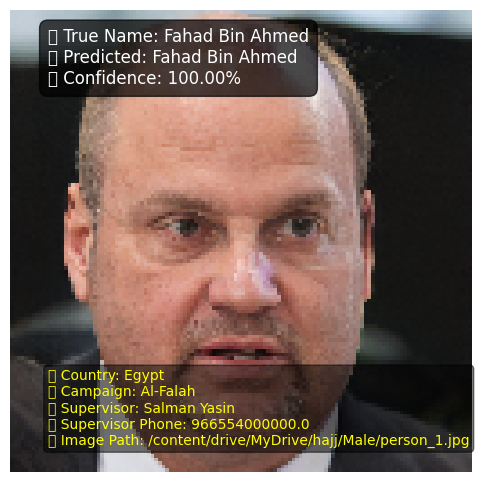

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np

def predict_person_by_image_path(labels_df, model, class_labels, image_path):
    """
    Predict the name of a person given an image path.
    The function searches for the image in the CSV and retrieves associated data.
    """
    # البحث عن الصف الذي يحتوي على نفس مسار الصورة
    matched_rows = labels_df[labels_df["Updated_Image_Path"] == image_path]

    if matched_rows.empty:
        print(f"⚠️ No matching record found for image: {image_path}")
        return

    # استخراج المعلومات من ملف CSV
    selected_row = matched_rows.iloc[0]  # أول صف متطابق
    true_label = selected_row["Name"]
    full_info = selected_row.to_dict()  # جميع المعلومات المرتبطة بالصورة

    # تحميل ومعالجة الصورة
    try:
        img = load_img(image_path, target_size=(128, 128))  # تعديل الحجم
        img_array = img_to_array(img) / 255.0  # تطبيع الصورة
        img_array = np.expand_dims(img_array, axis=0)  # إضافة بُعد إضافي للنموذج
    except FileNotFoundError:
        print(f"⚠️ Image not found: {image_path}")
        return

    # التنبؤ باستخدام النموذج
    predictions = model.predict(img_array)
    predicted_class_index = np.argmax(predictions)  # استخراج الفئة المتوقعة
    predicted_class_name = class_labels[predicted_class_index]  # اسم الفئة المتوقعة
    confidence = predictions[0][predicted_class_index]  # نسبة الثقة

    # عرض الصورة مع التوقعات والمعلومات
    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.axis('off')

    # تنسيق النصوص
    text_info = f"✅ True Name: {true_label}\n🔮 Predicted: {predicted_class_name}\n📊 Confidence: {confidence:.2%}"
    additional_info = "\n".join([f"🔹 {key}: {value}" for key, value in full_info.items() if key not in ["Updated_Image_Path", "Name"]])

    # إضافة النصوص على الصورة
    plt.text(10, 20, text_info, fontsize=12, color='white',
             bbox=dict(facecolor='black', alpha=0.7, boxstyle="round,pad=0.5"))
    plt.text(10, 120, additional_info, fontsize=10, color='yellow',
             bbox=dict(facecolor='black', alpha=0.5, boxstyle="round,pad=0.3"))

    # عرض الصورة
    plt.show()

# ✅ أدخل مسار الصورة هنا
image_path = "/content/drive/MyDrive/hajj/Male/20220901_155942_8eb5229c50384de783d3bcc8af34e4d3.png"

# استدعاء الدالة مع الصورة
predict_person_by_image_path(labels_df, model, unique_labels, image_path)

# MODEL3

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# بناء النموذج
model = Sequential([
    # طبقة الالتفاف الأولى
    Conv2D(32, (3, 3), activation='relu', input_shape=(128, 128, 3)),
    MaxPooling2D((2, 2)),

    # طبقة الالتفاف الثانية
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # طبقة الالتفاف الثالثة
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # طبقة تسطيح
    Flatten(),

    # طبقة كثيفة
    Dense(128, activation='relu'),
    Dropout(0.5),

    # الطبقة النهائية (عدد الوحدات = عدد الفئات)
    Dense(80, activation='softmax')  # عدد الفئات = 80
])

# تجميع النموذج
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# عرض ملخص النموذج
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_13 (Conv2D)                   │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_13 (MaxPooling2D)      │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_14 (Conv2D)                   │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_14 (MaxPooling2D)      │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_15 (Conv2D)                   │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_15 (MaxPooling2D)      │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_5 (Flatten)                  │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 80)                  │          10,320 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,314,960 (12.65 MB)

 Trainable params: 3,314,960 (12.65 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# تدريب النموذج
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    batch_size=32,  # حجم الدفعة
    epochs=20  # عدد العصور
)

Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 107s 1s/step - accuracy: 0.0128 - loss: 4.4135 - val_accuracy: 0.0137 - val_loss: 4.3832
Epoch 2/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 139s 1s/step - accuracy: 0.0144 - loss: 4.3817 - val_accuracy: 0.0237 - val_loss: 4.3655
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 144s 1s/step - accuracy: 0.0252 - loss: 4.3349 - val_accuracy: 0.0325 - val_loss: 4.2331
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.0505 - loss: 4.1136 - val_accuracy: 0.0911 - val_loss: 3.9680
Epoch 5/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 140s 1s/step - accuracy: 0.1289 - loss: 3.6446 - val_accuracy: 0.1860 - val_loss: 3.5143
Epoch 6/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 105s 1s/step - accuracy: 0.2878 - loss: 2.8567 - val_accuracy: 0.3208 - val_loss: 3.0476
Epoch 7/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.4368 - loss: 2.2102 - val_accuracy: 0.5381 - val_loss: 2.4245
Epoch 8/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.5515 - loss: 1.6304 - val_accu

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"دقة الاختبار: {test_accuracy * 100:.2f}%")

26/26 ━━━━━━━━━━━━━━━━━━━━ 9s 331ms/step - accuracy: 0.8015 - loss: 1.6723
دقة الاختبار: 80.90%


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


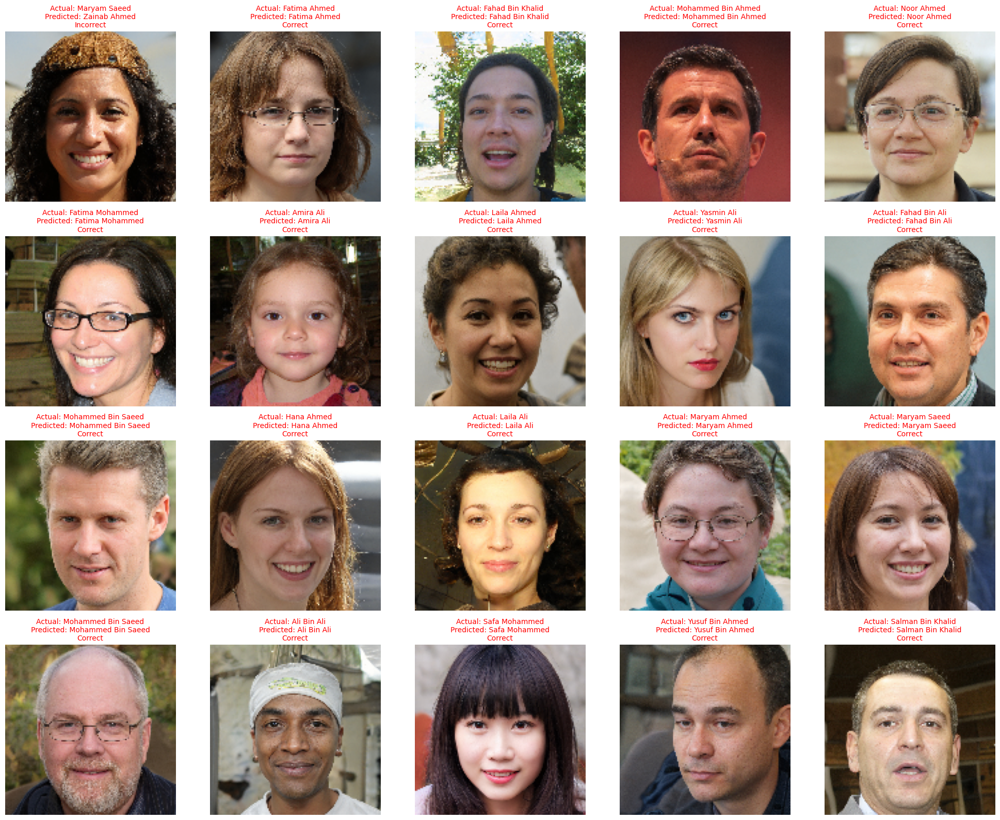

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# List of class labels the model was trained on
class_labels = unique_labels  # The names or classes used during training

def predict_and_display_multiple(labels_df, model, num_people=20, columns=5):
    """
    Function to display multiple images (e.g., 20 people) in a grid.
    Shows actual labels, predicted labels, and whether the prediction is correct.
    """
    # Randomly select people from the dataset
    selected_rows = labels_df.sample(min(num_people, len(labels_df)))

    # Set up the grid dimensions
    rows = (num_people + columns - 1) // columns  # Calculate required rows
    plt.figure(figsize=(columns * 4, rows * 4))  # Adjust figure size dynamically

    for i, (_, row) in enumerate(selected_rows.iterrows()):
        # Extract image path and actual label
        img_path = row["Updated_Image_Path"]
        actual_label = row["Name"]

        # Load and preprocess the image
        try:
            img = load_img(img_path, target_size=(128, 128))  # Resize to match training input
        except FileNotFoundError:
            print(f"⚠️ Image not found: {img_path}")
            continue

        img_array = img_to_array(img) / 255.0  # Normalize values
        img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension

        # Pass the image to the model to get predictions
        predictions = model.predict(img_array)
        predicted_class_index = np.argmax(predictions)
        predicted_class_name = class_labels[predicted_class_index]
        is_correct = "Correct" if actual_label == predicted_class_name else "Incorrect"

        # Plot the image
        plt.subplot(rows, columns, i + 1)  # Arrange images in a grid
        plt.imshow(img)
        plt.axis('off')
        plt.title(f"Actual: {actual_label}\nPredicted: {predicted_class_name}\n{is_correct}",
                  fontsize=10, color='blue' if is_correct == "✅ Correct" else 'red')

    plt.tight_layout()
    plt.show()


# 🟢 Run the function to display 20 people in a grid of 4 rows x 5 columns
predict_and_display_multiple(labels_df, model, num_people=20, columns=5)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


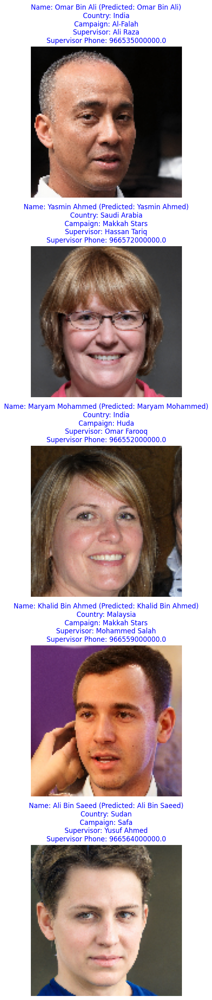

In [ ]:
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np

def display_images_with_details(labels_df, model, num_images=5):
    """
    Display images with additional details (Name, Country, Campaign, Supervisor, Supervisor Phone).
    """
    # Select random rows from the dataset
    selected_rows = labels_df.sample(num_images)

    # Set up the grid for displaying images
    plt.figure(figsize=(10, num_images * 5))  # Dynamically adjust figure size

    for i, (_, row) in enumerate(selected_rows.iterrows()):
        # Extract image path and additional details
        img_path = row["Updated_Image_Path"]
        name = row["Name"]
        country = row["Country"]
        campaign = row["Campaign"]
        supervisor = row["Supervisor"]
        supervisor_phone = row["Supervisor Phone"]

        # Load and preprocess the image
        try:
            img = load_img(img_path, target_size=(128, 128))  # Resize to match model input
        except FileNotFoundError:
            print(f"⚠️ Image not found: {img_path}")
            continue

        img_array = img_to_array(img) / 255.0  # Normalize values
        img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension

        # Pass the image to the model for predictions
        predictions = model.predict(img_array)
        predicted_class_index = np.argmax(predictions)
        predicted_class_name = unique_labels[predicted_class_index]  # Predicted label

        # Plot the image
        plt.subplot(num_images, 1, i + 1)  # Display each image in its own row
        plt.imshow(img)
        plt.axis('off')

        # Add all details below the image
        details = (
            f"Name: {name} (Predicted: {predicted_class_name})\n"
            f"Country: {country}\n"
            f"Campaign: {campaign}\n"
            f"Supervisor: {supervisor}\n"
            f"Supervisor Phone: {supervisor_phone}"
        )
        plt.title(details, fontsize=12, color='blue')

    plt.tight_layout()
    plt.show()


# 🟢 Run the function to display 5 images with their details
display_images_with_details(labels_df, model, num_images=5)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


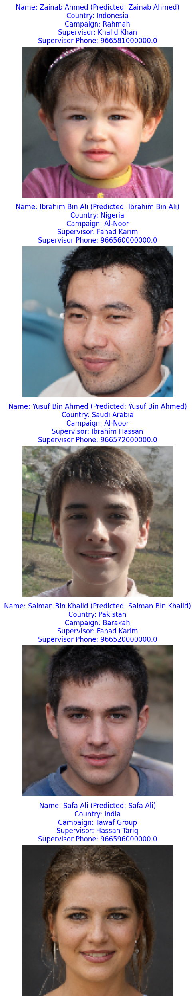

In [ ]:
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np

def display_images_with_details(labels_df, model, num_images=5):
    """
    Display images with additional details (Name, Country, Campaign, Supervisor, Supervisor Phone).
    """
    # Select random rows from the dataset
    selected_rows = labels_df.sample(num_images)

    # Set up the grid for displaying images
    plt.figure(figsize=(10, num_images * 5))  # Dynamically adjust figure size

    for i, (_, row) in enumerate(selected_rows.iterrows()):
        # Extract image path and additional details
        img_path = row["Updated_Image_Path"]
        name = row["Name"]
        country = row["Country"]
        campaign = row["Campaign"]
        supervisor = row["Supervisor"]
        supervisor_phone = row["Supervisor Phone"]

        # Load and preprocess the image
        try:
            img = load_img(img_path, target_size=(128, 128))  # Resize to match model input
        except FileNotFoundError:
            print(f"⚠️ Image not found: {img_path}")
            continue

        img_array = img_to_array(img) / 255.0  # Normalize values
        img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension

        # Pass the image to the model for predictions
        predictions = model.predict(img_array)
        predicted_class_index = np.argmax(predictions)
        predicted_class_name = unique_labels[predicted_class_index]  # Predicted label

        # Plot the image
        plt.subplot(num_images, 1, i + 1)  # Display each image in its own row
        plt.imshow(img)
        plt.axis('off')

        # Add all details below the image
        details = (
            f"Name: {name} (Predicted: {predicted_class_name})\n"
            f"Country: {country}\n"
            f"Campaign: {campaign}\n"
            f"Supervisor: {supervisor}\n"
            f"Supervisor Phone: {supervisor_phone}"
        )
        plt.title(details, fontsize=12, color='blue')

    plt.tight_layout()
    plt.show()


# 🟢 Run the function to display 5 images with their details
display_images_with_details(labels_df, model, num_images=5)

# Visualization of Model Predictions

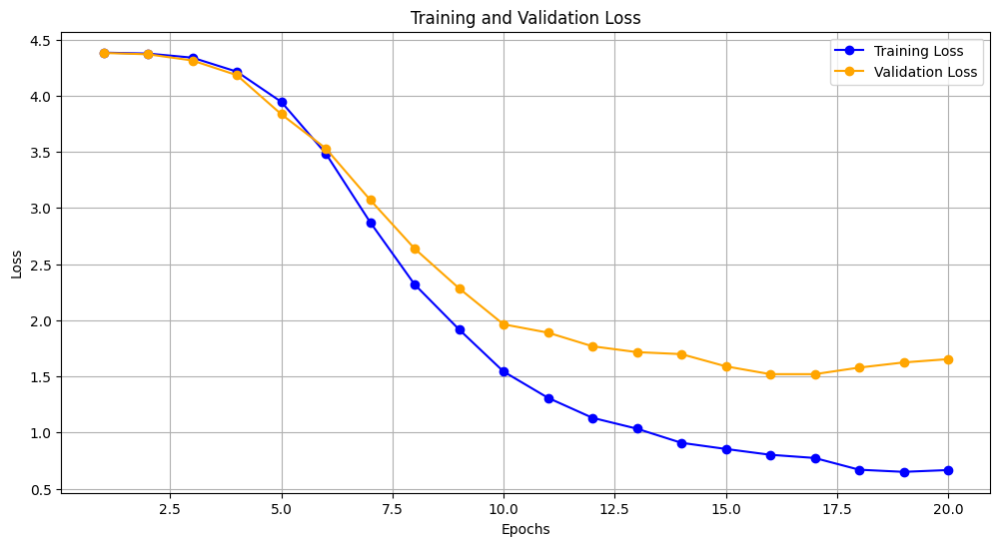

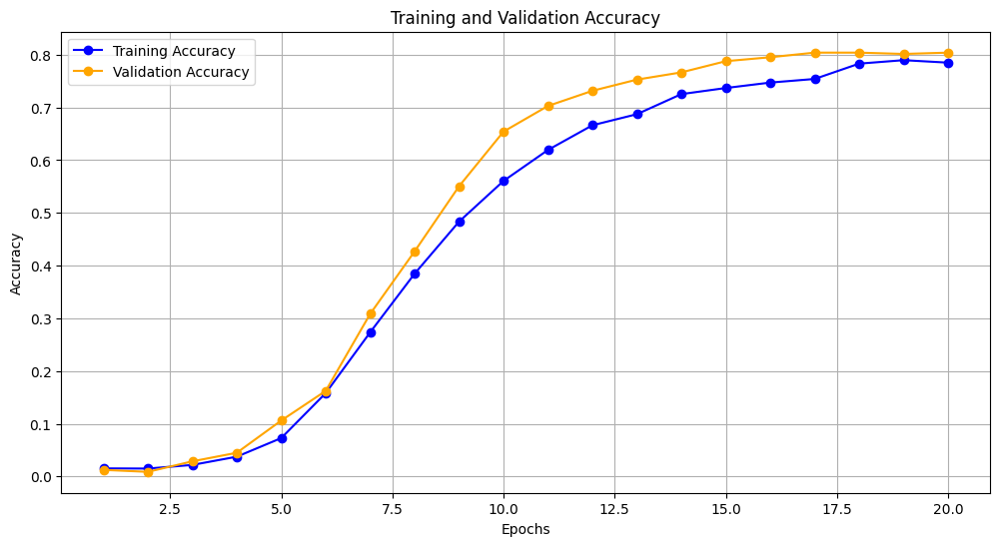

In [ ]:
import matplotlib.pyplot as plt

def plot_training_history(history):
    """
    Plot training and validation loss and accuracy over epochs.
    """
    # Extract metrics from the history object
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    accuracy = history.history['accuracy']
    val_accuracy = history.history['val_accuracy']
    epochs = range(1, len(loss) + 1)

    # Plot Loss
    plt.figure(figsize=(12, 6))
    plt.plot(epochs, loss, label='Training Loss', color='blue', marker='o')
    plt.plot(epochs, val_loss, label='Validation Loss', color='orange', marker='o')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid()
    plt.show()

    # Plot Accuracy
    plt.figure(figsize=(12, 6))
    plt.plot(epochs, accuracy, label='Training Accuracy', color='blue', marker='o')
    plt.plot(epochs, val_accuracy, label='Validation Accuracy', color='orange', marker='o')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid()
    plt.show()


# 🟢 Call the function after training your model
# Example:
# history = model.fit(...)  # Train your model
plot_training_history(history)


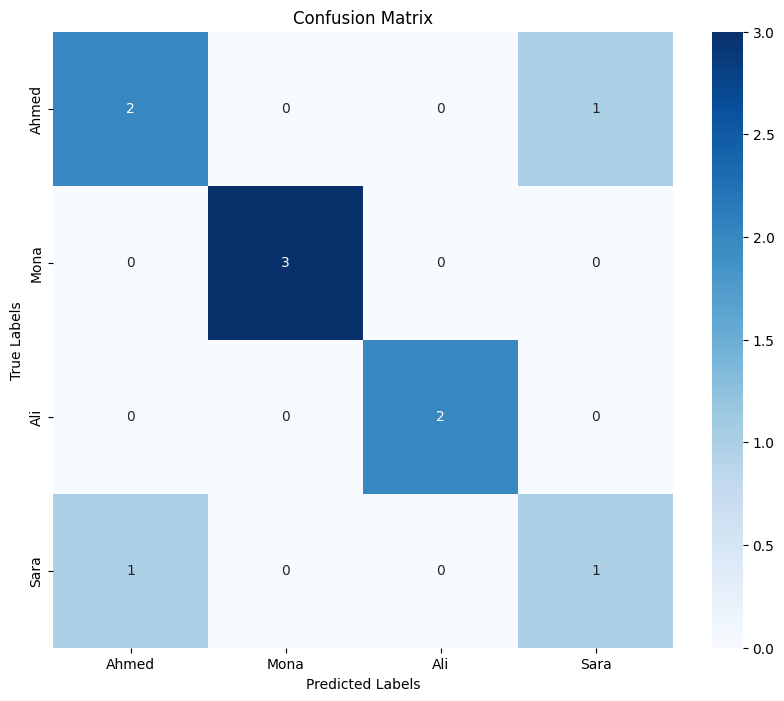


Classification Report:
              precision    recall  f1-score   support

       Ahmed       0.67      0.67      0.67         3
        Mona       1.00      1.00      1.00         2
         Ali       1.00      1.00      1.00         3
        Sara       0.50      0.50      0.50         2

    accuracy                           0.80        10
   macro avg       0.79      0.79      0.79        10
weighted avg       0.80      0.80      0.80        10



In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

def plot_confusion_matrix_from_labels(y_true, y_pred, labels):
    """
    Plot a Confusion Matrix using true labels and predicted labels.
    """
    # Compute confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=labels)

    # Plot confusion matrix as a heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title('Confusion Matrix')
    plt.show()

    # Print classification report
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=labels))


# Example usage
# Assuming y_true and y_pred are lists or numpy arrays of true and predicted labels
y_true = ['Ahmed', 'Mona', 'Ali', 'Ahmed', 'Sara', 'Mona', 'Ali', 'Sara', 'Ahmed', 'Mona']
y_pred = ['Ahmed', 'Mona', 'Ali', 'Sara', 'Sara', 'Mona', 'Ali', 'Ahmed', 'Ahmed', 'Mona']
labels = ['Ahmed', 'Mona', 'Ali', 'Sara']  # Unique label names

plot_confusion_matrix_from_labels(y_true, y_pred, labels)


# Face Recognition

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step

📌 **Image Information from CSV:**
🔹 Name: Fahad Bin Ahmed
🔹 Country: Egypt
🔹 Campaign: Al-Falah
🔹 Supervisor: Salman Yasin
🔹 Supervisor Phone: 966554000000.0
🔹 Image Path: /content/drive/MyDrive/hajj/Male/person_1.jpg
🔹 Updated_Image_Path: /content/drive/MyDrive/hajj/Male/20220901_155942_8eb5229c50384de783d3bcc8af34e4d3.png

🎯 **Prediction Results:**
✅ True Name: Fahad Bin Ahmed
🔮 Predicted Name: Fahad Bin Ahmed
📊 Confidence: 100.00%


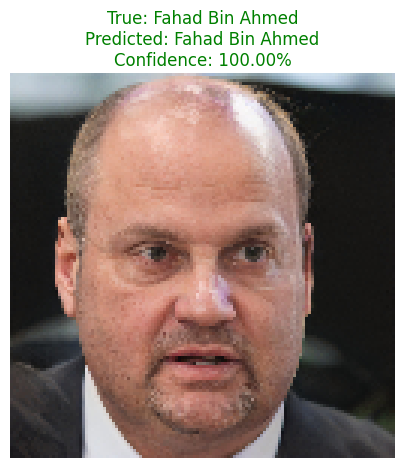

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np

def predict_person_by_image_path(labels_df, model, class_labels, image_path):
    """
    Predict the name of a person given an image path.
    The function searches for the image in the CSV and retrieves associated data.
    """
    # البحث عن الصف الذي يحتوي على نفس مسار الصورة
    matched_rows = labels_df[labels_df["Updated_Image_Path"] == image_path]

    if matched_rows.empty:
        print(f"⚠️ No matching record found for image: {image_path}")
        return

    # استخراج المعلومات من ملف CSV
    selected_row = matched_rows.iloc[0]  # أول صف متطابق
    true_label = selected_row["Name"]
    full_info = selected_row.to_dict()  # جميع المعلومات المرتبطة بالصورة

    # تحميل ومعالجة الصورة
    try:
        img = load_img(image_path, target_size=(128, 128))  # تعديل الحجم
        img_array = img_to_array(img) / 255.0  # تطبيع الصورة
        img_array = np.expand_dims(img_array, axis=0)  # إضافة بُعد إضافي للنموذج
    except FileNotFoundError:
        print(f"⚠️ Image not found: {image_path}")
        return

    # التنبؤ باستخدام النموذج
    predictions = model.predict(img_array)
    predicted_class_index = np.argmax(predictions)  # استخراج الفئة المتوقعة
    predicted_class_name = class_labels[predicted_class_index]  # اسم الفئة المتوقعة
    confidence = predictions[0][predicted_class_index]  # نسبة الثقة

    # طباعة جميع المعلومات من ملف CSV
    print("\n📌 **Image Information from CSV:**")
    for key, value in full_info.items():
        print(f"🔹 {key}: {value}")

    print("\n🎯 **Prediction Results:**")
    print(f"✅ True Name: {true_label}")
    print(f"🔮 Predicted Name: {predicted_class_name}")
    print(f"📊 Confidence: {confidence:.2%}")

    # عرض الصورة مع التوقعات
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"True: {true_label}\nPredicted: {predicted_class_name}\nConfidence: {confidence:.2%}",
              color='green' if true_label == predicted_class_name else 'red')
    plt.show()




# ✅ أدخل مسار الصورة هنا
image_path = "/content/drive/MyDrive/hajj/Male/20220901_155942_8eb5229c50384de783d3bcc8af34e4d3.png"

# استدعاء الدالة مع الصورة
predict_person_by_image_path(labels_df, model, unique_labels, image_path)

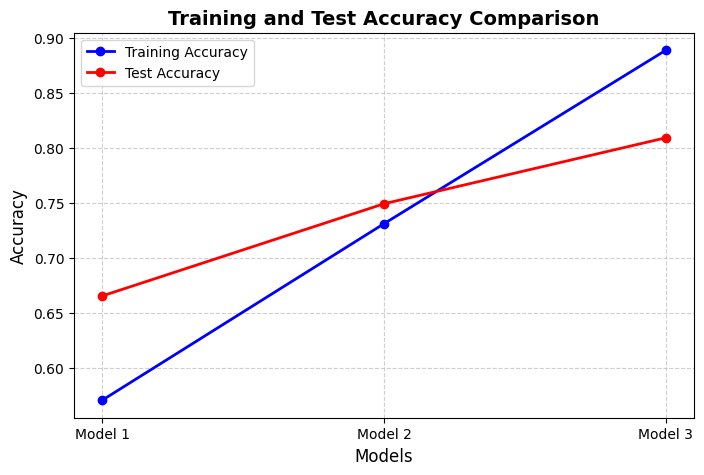

In [ ]:
import matplotlib.pyplot as plt

# بيانات النماذج بناءً على المعلومات الحقيقية
models = ["Model 1", "Model 2", "Model 3"]
training_accuracy = [0.5707, 0.7310, 0.8885]  # آخر قيمة لدقة التدريب لكل نموذج بعد التحديث
test_accuracy = [0.6654, 0.7491, 0.8090]  # دقة الاختبار لكل نموذج بعد التحديث

# رسم البيانات باستخدام خط
fig, ax = plt.subplots(figsize=(8, 5))

# رسم خطوط الدقة التدريبية والاختبار
ax.plot(models, training_accuracy, marker='o', label='Training Accuracy', color='blue', linewidth=2)
ax.plot(models, test_accuracy, marker='o', label='Test Accuracy', color='red', linewidth=2)

# إضافة العناوين والتنسيق
ax.set_xlabel("Models", fontsize=12)
ax.set_ylabel("Accuracy", fontsize=12)
ax.set_title("Training and Test Accuracy Comparison", fontsize=14, fontweight='bold')

# إضافة خطوط الشبكة لتحسين وضوح الرسم
ax.grid(True, linestyle='--', alpha=0.6)

# إضافة وسيلة إيضاح
ax.legend(fontsize=10)

# عرض الرسم
plt.show()